In [5]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

def fred(series_id):
    url = f"https://fred.stlouisfed.org/graph/fredgraph.csv?id={series_id}"
    df = pd.read_csv(url)
    df.columns = ["date", series_id]
    df["date"] = pd.to_datetime(df["date"])
    df[series_id] = pd.to_numeric(df[series_id], errors="coerce")
    return df.set_index("date")

cpi = fred("CPIAUCSL")
mich = fred("MICH")
print(cpi.tail(3))
print(mich.tail(3))

            CPIAUCSL
date                
2026-07-01   332.813
2026-08-01   334.131
2026-09-01   336.298
            MICH
date            
2026-07-01   4.2
2026-08-01   4.0
2026-09-01   4.6


In [7]:
cpi["cpi_yoy"] = cpi["CPIAUCSL"].pct_change(12) * 100

df = cpi[["cpi_yoy"]].join(mich.rename(columns={"MICH": "mich_expect"}), how="inner")
df = df.loc["2021-01-01":].dropna()
print(df.shape)
df.head()

(69, 2)


/var/folders/ww/qktpngmx2q5634g56kllbhnr0000gn/T/ipykernel_60901/1662630761.py:1: FutureWarning: The default fill_method='pad' in Series.pct_change is deprecated and will be removed in a future version. Either fill in any non-leading NA values prior to calling pct_change or specify 'fill_method=None' to not fill NA values.
  cpi["cpi_yoy"] = cpi["CPIAUCSL"].pct_change(12) * 100


,cpi_yoy,mich_expect
date,,
2021-01-01,1.373844,3.0
2021-02-01,1.669817,3.3
2021-03-01,2.667819,3.1
2021-04-01,4.133077,3.4
2021-05-01,4.918257,4.6


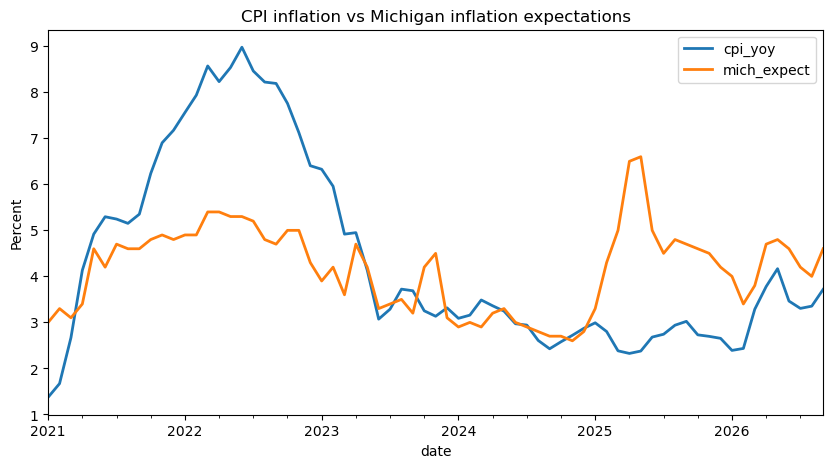

In [9]:
ax = df.plot(figsize=(10, 5), lw=2)
ax.set_title("CPI inflation vs Michigan inflation expectations")
ax.set_ylabel("Percent")
plt.show()

In [11]:
df.to_csv("../data/official.csv")
print("saved")

saved
